In [ ]:
# # Session 10.2 — Categorical Visuals: Countplot & Barplot
# # આજે આપણે Seaborn ના બે ખૂબ જ મહત્વના charts શીખીશું: sns.countplot() અને sns.barplot().

# # તમે trainer તરીકે શીખી રહ્યા છો, એટલે દરેક concept ને ત્રણ રીતે સમજીએ: Theory → Python Practical → Student ને કેવી રીતે સમજાવવું.
# # 1. Learning objectives
# # આ session પૂર્ણ થયા પછી તમે સમજી શકશો:
# # - sns.countplot() વડે category પ્રમાણે records ની સંખ્યા ગણવી.
# # - sns.barplot() વડે categories ના numerical values ની સરખામણી કરવી.
# # - estimator વડે mean, sum જેવી aggregation કરવી.
# # - errorbar વડે uncertainty દર્શાવવી અથવા તેને દૂર કરવી.
# # - hue, order, palette અને orient જેવા parameters નો ઉપયોગ કરવો.
# # 2. Countplot અને Barplot વચ્ચેનો તફાવત

# # Countplot — કેટલા records છે?

# # ઉદાહરણ: IT department માં કેટલા વિદ્યાર્થીઓ છે અને Computer department માં કેટલા છે?

# # Function: sns.countplot()

# # Barplot — Numerical value કેટલી છે?

# # ઉદાહરણ: IT અને Computer department ના વિદ્યાર્થીઓના average marks કેટલા છે?

# # Function: sns.barplot()

# Feature	  Countplot()	        barplot()
# હેતુ	       Category નો count	  Category પ્રમાણે numerical summary
# Y-axis	 Records ની સંખ્યા	        સામાન્ય રીતે mean
# y column જરૂરી?	નહીં	        હા, જો x પર categories હોય
# estimator	લાગુ પડતું નથી	    Mean, sum વગેરે
# Example	કેટલા students IT માં છે?	IT ના average marks કેટલા છે?

In [2]:
# 3. Step 1 — Dataset તૈયાર કરો
# આપણો sample dataset student performance પર આધારિત છે.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Student": [
        "Amit", "Neha", "Ravi", "Pooja",
        "Karan", "Meera", "Jay", "Priya",
        "Rahul", "Nisha"
    ],
    "Department": [
        "IT", "IT", "Computer", "Computer",
        "IT", "Computer", "IT", "Computer",
        "IT", "Computer"
    ],
    "Python": [85, 92, 70, 88, 65, 95, 78, 82, 90, 86],
    "SQL": [78, 88, 75, 90, 68, 92, 80, 85, 84, 89],
    "Gender": [
        "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female",
        "Male", "Female"
    ]
}

df = pd.DataFrame(data)

print(df)

  Student Department  Python  SQL  Gender
0    Amit         IT      85   78    Male
1    Neha         IT      92   88  Female
2    Ravi   Computer      70   75    Male
3   Pooja   Computer      88   90  Female
4   Karan         IT      65   68    Male
5   Meera   Computer      95   92  Female
6     Jay         IT      78   80    Male
7   Priya   Computer      82   85  Female
8   Rahul         IT      90   84    Male
9   Nisha   Computer      86   89  Female


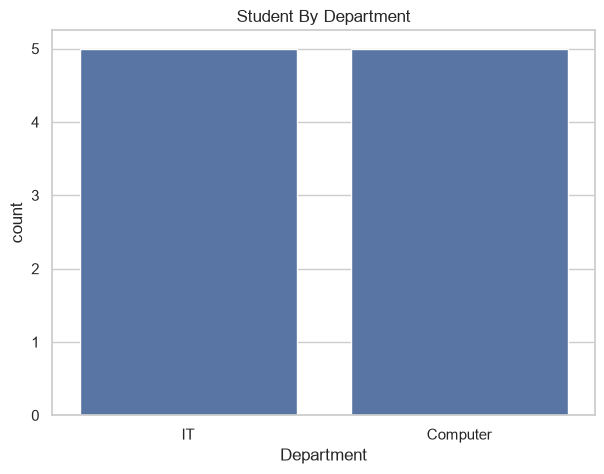

In [4]:
# 4. Step 2 — sns.countplot() નો ઉપયોગ
# Countplot દરેક category માં કેટલા records છે તે બતાવે છે.

sns.set_theme(style="whitegrid")

fig,ax = plt.subplots(figsize=(7,5))

sns.countplot(
    data = df,
    x = "Department",
    ax=ax
)

ax.set_title("Student By Department")
ax.set_xlabel("Department")
ax.set_label("Number of Students")

plt.show()


# Output કેવી રીતે સમજવું?
# - X-axis પર IT અને Computer categories હશે.
# - Y-axis પર દરેક department માં students ની સંખ્યા હશે.
# - બંને departments માં પાંચ students હોવાથી બંને bars ની height સમાન હશે.
# Countplot માં ઉપયોગી parameters
# Parameter	ઉપયોગ
# data=df	DataFrame પસંદ કરે છે
# x="Department"	X-axis પર category
# hue="Gender"	Gender પ્રમાણે અલગ colors
# order=[...]	Categories નો ક્રમ નક્કી કરે છે
# palette="deep"	Color palette પસંદ કરે છે
# orient="h"	Horizontal chart માટે orientation


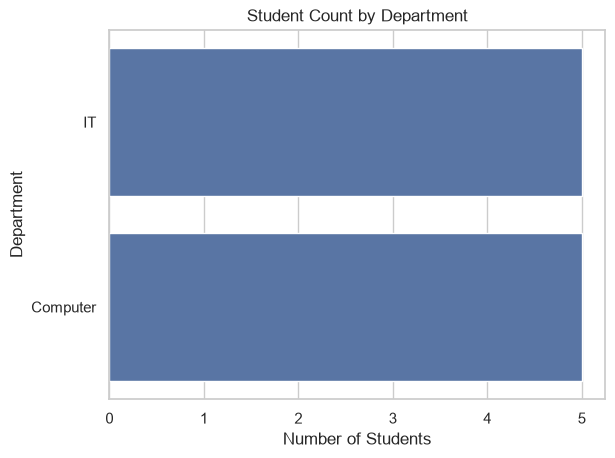

In [ ]:
# Horizontal Countplot

sns.countplot(
    data=df,
    y="Department",
    order=["IT", "Computer"]
)

plt.title("Student Count by Department")
plt.xlabel("Number of Students")
plt.ylabel("Department")
plt.show()

# અહીં y="Department" હોવાથી categories vertical axis પર દેખાશે અને count horizontal axis પર દેખાશે

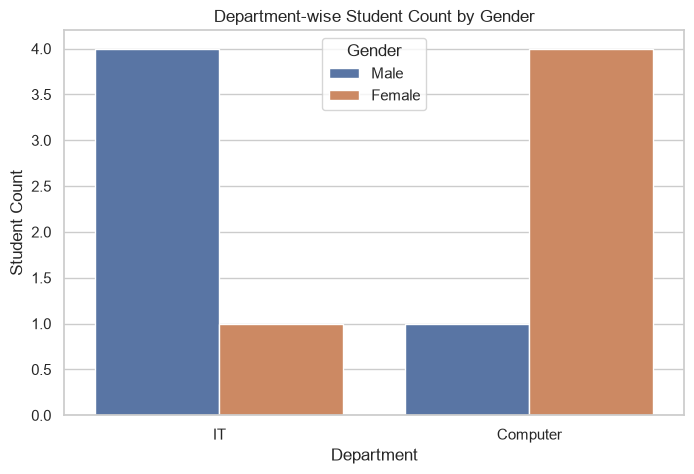

In [ ]:
# 5. Step 3 — hue વડે category ને divide કરવી

# ધારો કે તમને દરેક department માં Male અને Female students ની સંખ્યા જાણવી છે.

fig,ax = plt.subplots(figsize=(8,5))

sns.countplot(
    data=df,
    x="Department",
    hue="Gender", # gender ma all deparment under geneder bar deffernt banavase
    ax=ax
)

ax.set_title("Department-wise Student Count by Gender")
ax.set_xlabel("Department")
ax.set_ylabel("Student Count")
ax.legend(title="Gender")

plt.show()

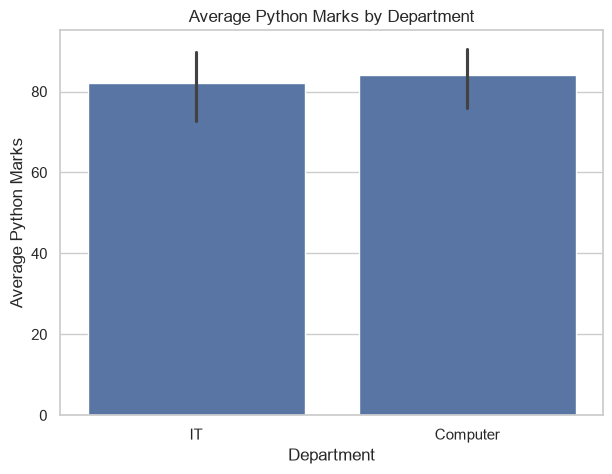

In [ ]:
# 6. Step 4 — sns.barplot() શું કરે છે?
# હવે આપણે department પ્રમાણે average Python marks શોધીશું.

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Department",
    y="Python",
    ax=ax
)


ax.set_title("Average Python Marks by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Average Python Marks")

plt.show()

# barplot() માં જ્યારે x category અને y numerical value હોય, ત્યારે default રીતે દરેક category માટે y ની mean (average) value દર્શાવવામાં આવે છે.

# ઉદાહરણ તરીકે:

# IT mean = total marks / total value =answer 

# aa j computer ma 

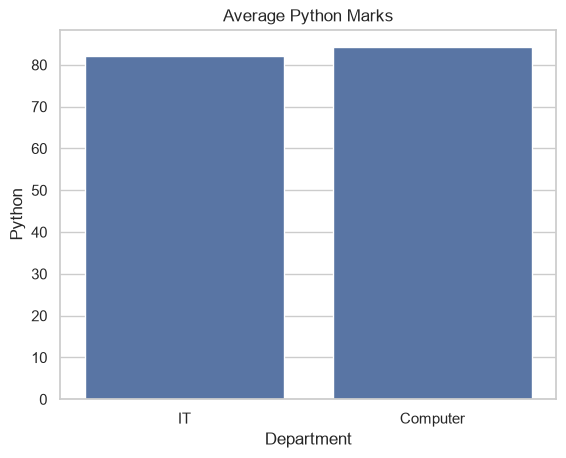

In [11]:
# 7. Step 5 — estimator વડે Mean અને Sum
# estimator parameter નક્કી કરે છે કે દરેક category ની numerical values માંથી કઈ summary કાઢવી

# A. Mean — Average marks

sns.barplot(
    data=df,
    x="Department",
    y="Python",
    estimator="mean",
    errorbar=None
)

plt.title("Average Python Marks")
plt.show()

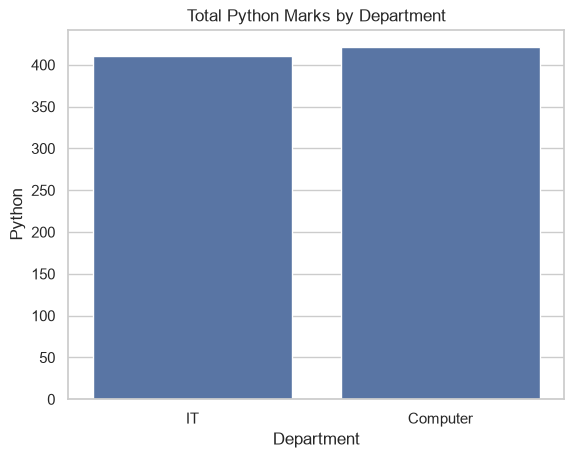

In [13]:
# B. Sum — કુલ marks
sns.barplot(
    data=df,
    x="Department",
    y="Python",
    estimator="sum",
    errorbar=None
)

plt.title("Total Python Marks by Department")
plt.show()

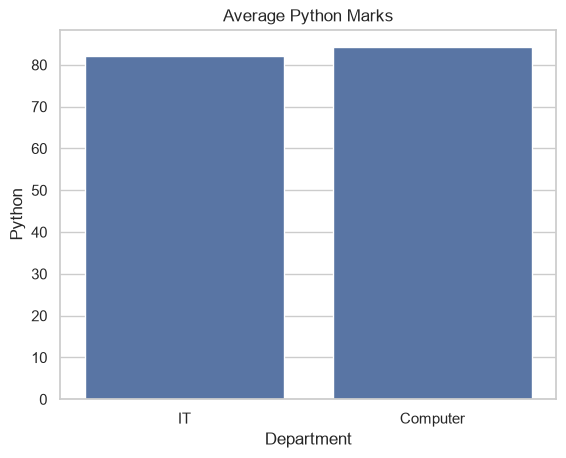

In [14]:
# Seaborn ના આધુનિક versions માં estimator સામાન્ય રીતે callable function તરીકે આપવામાં આવે છે. ઉપરના string examples ને બદલે આ રીતે લખવું વધુ યોગ્ય અને વિશ્વસનીય છે:
import numpy as np

# Average marks
sns.barplot(
    data=df,
    x="Department",
    y="Python",
    estimator=np.mean,
    errorbar=None
)

plt.title("Average Python Marks")
plt.show()


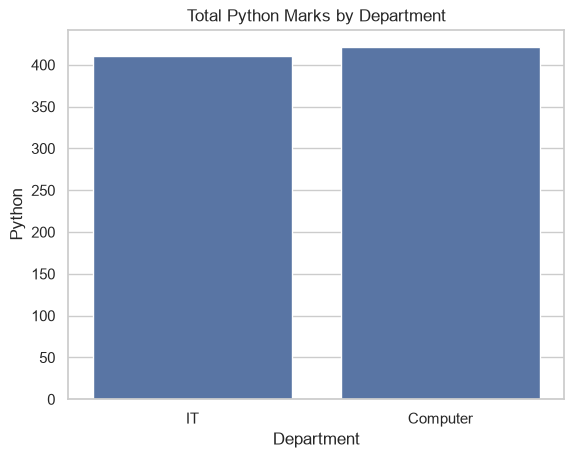

In [15]:
sns.barplot(
    data=df,
    x="Department",
    y="Python",
    estimator=np.sum,
    errorbar=None
)

plt.title("Total Python Marks by Department")
plt.show()

In [16]:
# અહીં np.mean અને np.sum NumPy ના functions છે. તેમને estimator તરીકે આપવાથી દરેક category માટે mean અથવા sum ની ગણતરી થાય છે.
# Estimator	અર્થ	ઉપયોગ
# np.mean	સરેરાશ	Average student marks
# np.sum	કુલ સરવાળો	Total sales અથવા total marks
# np.median	મધ્યસ્થ મૂલ્ય	Outliers હોય ત્યારે મધ્યસ્થનું વિશ્લેષણ
# len	Values ની સંખ્યા	Category માં observations ની સંખ્યા; સામાન્ય રીતે countplot વધુ સીધો વિકલ્પ છે

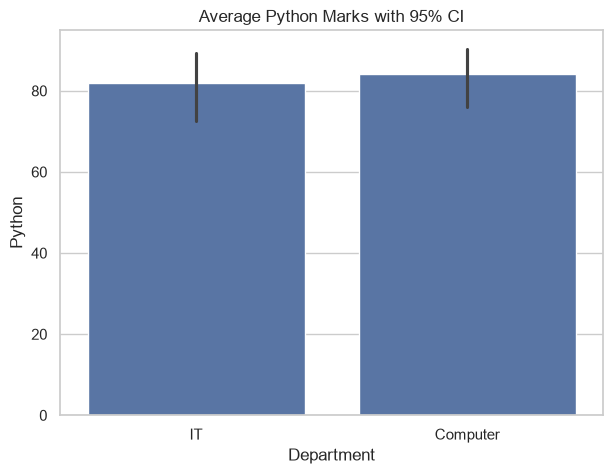

In [17]:
# 8. Step 6 — Confidence intervals અને errorbar
# Barplot માં bar ની ઉપર અથવા નીચે દેખાતી error bars ઘણી વખત estimate ની uncertainty દર્શાવે છે. Seaborn ના default barplot માં સામાન્ય રીતે mean માટે bootstrap confidence interval બતાવવામાં આવે છે.

# ઉદાહરણ:

fig, ax = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Department",
    y="Python",
    errorbar=("ci", 95),
    ax=ax
)

ax.set_title("Average Python Marks with 95% CI")
plt.show()

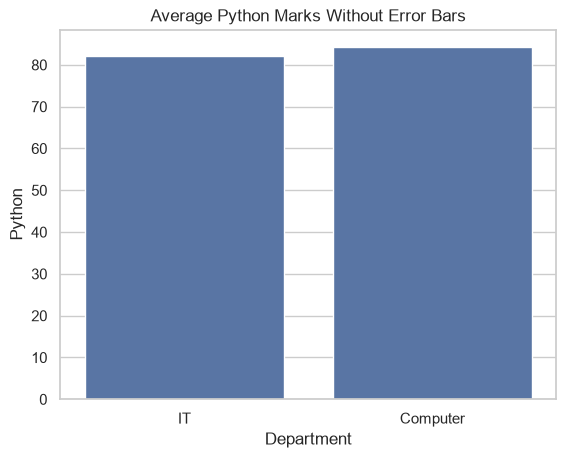

In [ ]:
# Confidence interval દૂર કરવો
# જો તમને ફક્ત bars જોઈએ અને error bars ન જોઈએ:
sns.barplot(
    data=df,
    x="Department",
    y="Python",
    errorbar=None
)

plt.title("Average Python Marks Without Error Bars")
plt.show()

# errorbar=("ci", 95) — 95% confidence interval દર્શાવે છે.
# errorbar=None — error bars દૂર કરે છે.

In [19]:
# 9. Step 7 — Real-world business example: Sales by Region
# હવે student data ના બદલે sales data પર બંને charts સમજીએ.

sales_df = pd.DataFrame({
    "Region": [
        "Ahmedabad", "Ahmedabad", "Ahmedabad",
        "Surat", "Surat", "Surat",
        "Rajkot", "Rajkot", "Rajkot"
    ],
    "Sales": [
        120, 150, 180,
        100, 130, 170,
        90, 110, 140
    ],
    "Product": [
        "Laptop", "Mobile", "Laptop",
        "Mobile", "Laptop", "Mobile",
        "Laptop", "Mobile", "Laptop"
    ]
})

print(sales_df)

      Region  Sales Product
0  Ahmedabad    120  Laptop
1  Ahmedabad    150  Mobile
2  Ahmedabad    180  Laptop
3      Surat    100  Mobile
4      Surat    130  Laptop
5      Surat    170  Mobile
6     Rajkot     90  Laptop
7     Rajkot    110  Mobile
8     Rajkot    140  Laptop


Text(0.5, 1.0, 'Number Of Sales records by Region')

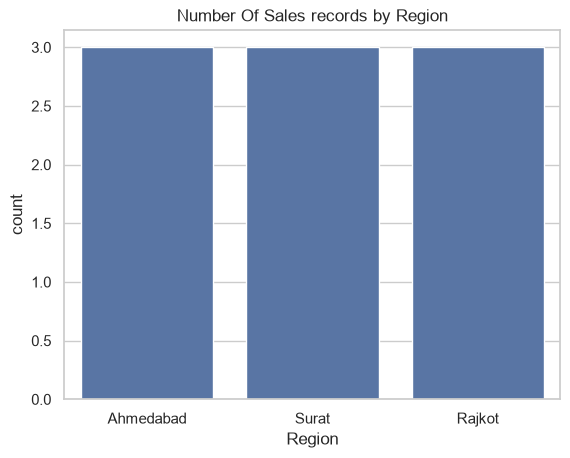

In [20]:
# A. દરેક region માં કેટલા sales records છે?

sns.countplot(
    data=sales_df,
    x="Region"
)

plt.title("Number Of Sales records by Region")

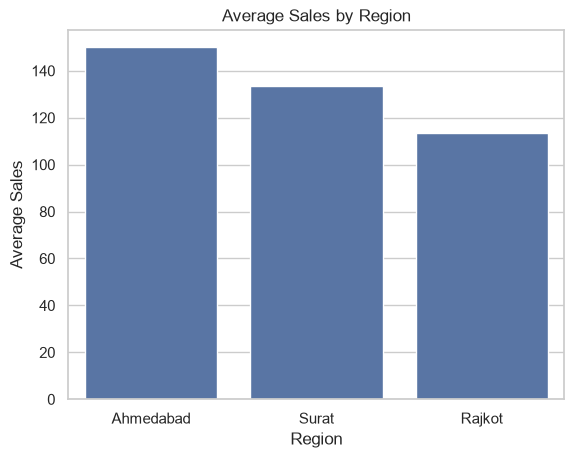

In [21]:
# B. દરેક region નું average sales કેટલું છે?

sns.barplot(
    data=sales_df,
    x="Region",
    y="Sales",
    errorbar=None
)

plt.title("Average Sales by Region")
plt.ylabel("Average Sales")
plt.show()

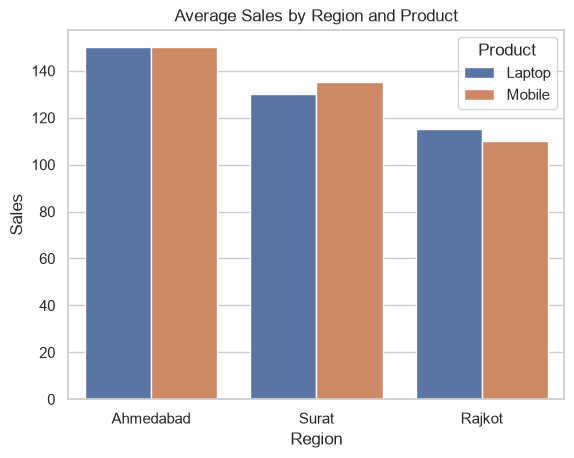

In [22]:
# C. Product પ્રમાણે average sales સરખાવો
sns.barplot(
    data=sales_df,
    x="Region",
    y="Sales",
    hue="Product",
    errorbar=None
)

plt.title("Average Sales by Region and Product")
plt.show()
